# Lab 01 – Dự đoán khối lượng chim cánh cụt

**Mã nhóm** [Điền mã nhóm]  
**Thành viên** [Điền họ tên và MSSV của 4 thành viên]

Chạy các cell theo thứ tự. M1–M4 là bốn vị trí để mỗi thành viên tự chọn một thuật toán hồi quy tuyến tính. Điền các mục **TODO** khi hoàn thiện bài nhóm.

## 1. Mô tả bài toán

Mục tiêu đề xuất là dự đoán khối lượng cơ thể, `body_mass_g` (g). Bộ biến mẫu gồm chiều dài cánh bơi, chiều dài và độ sâu mỏ, loài và giới tính. Sau EDA, nhóm chốt đầu vào dùng chung cho bốn thuật toán.

**TODO** Viết động cơ chọn bài toán, câu hỏi nghiên cứu và giải thích lựa chọn bộ biến đầu vào.

## 2. Nạp và khám phá dữ liệu

Notebook đọc CSV trong thư mục `data/`. Nguồn dữ liệu là bản `penguins` đã đơn giản hóa. [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/)

In [1]:
from pathlib import Path
import sys

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path.cwd()
if not (project_root / "data" / "penguins.csv").is_file():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from source.modeling import CATEGORICAL, FEATURES, TARGET, load_penguins, regression_metrics, split_penguins
from source.models import m1, m2, m3, m4

LABELS = {
    "flipper_length_mm": "Chiều dài cánh bơi (mm)",
    "bill_length_mm": "Chiều dài mỏ (mm)",
    "bill_depth_mm": "Độ sâu mỏ (mm)",
    "year": "Năm quan sát",
    "species": "Loài",
    "island": "Đảo",
    "sex": "Giới tính",
    "body_mass_g": "Khối lượng cơ thể (g)",
}

penguins = load_penguins()
print(f"Dữ liệu gốc: {len(penguins)} dòng, {penguins.shape[1]} cột")

Dữ liệu gốc: 344 dòng, 8 cột


### Chia tập và xem dữ liệu huấn luyện

Loại các dòng thiếu giá trị đích vì chúng không có nhãn để huấn luyện hoặc đánh giá. Dùng một lần chia 80/20 với seed 42 cho toàn bộ các mô hình. Pipeline học cách điền thiếu, chuẩn hóa và mã hóa trên tập huấn luyện.

Các bảng và biểu đồ bên dưới dùng `train_data` để đề xuất bộ biến. Tập test được dành cho lượt đánh giá sau khi chốt cấu hình.

In [2]:
train_data, test_data = split_penguins(penguins)
y_train = train_data[TARGET]
y_test = test_data[TARGET]

print(f"Huấn luyện: {len(train_data)} dòng | Kiểm tra: {len(test_data)} dòng")

print(f"Dòng thiếu biến đích trong CSV: {penguins[TARGET].isna().sum()}")
print(f"Dòng trùng toàn bộ cột trong tập train: {train_data.duplicated().sum()}")
display(train_data.head())
display(pd.DataFrame({
    "Kiểu dữ liệu": train_data.dtypes.astype(str),
    "Số giá trị thiếu": train_data.isna().sum(),
    "Tỷ lệ thiếu (%)": train_data.isna().mean().mul(100).round(2),
}))

Huấn luyện: 273 dòng | Kiểm tra: 69 dòng
Dòng thiếu biến đích trong CSV: 2
Dòng trùng toàn bộ cột trong tập train: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
115,Adelie,Biscoe,42.7,18.3,196.0,4075.0,male,2009
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
138,Adelie,Dream,37.0,16.5,185.0,3400.0,female,2009
334,Chinstrap,Dream,50.2,18.8,202.0,3800.0,male,2009
306,Chinstrap,Dream,40.9,16.6,187.0,3200.0,female,2008


,Kiểu dữ liệu,Số giá trị thiếu,Tỷ lệ thiếu (%)
species,object,0,0.00
island,object,0,0.00
bill_length_mm,float64,0,0.00
bill_depth_mm,float64,0,0.00
flipper_length_mm,float64,0,0.00
body_mass_g,float64,0,0.00
sex,object,5,1.83
year,int64,0,0.00


### Từ biểu đồ gộp đến giả thuyết phân nhóm

Vẽ khối lượng theo từng số đo trên toàn bộ tập train với cùng một màu cho mọi cá thể. Đối chiếu ba biểu đồ với Pearson gộp (trang PDF 109 của Bùi Tiến Lên, *Phân tích dữ liệu*, 2023).

Biểu đồ độ sâu mỏ nổi bật với hai vùng điểm: nhiều cá thể nặng có mỏ nông, còn nhiều cá thể nhẹ hơn có mỏ sâu. Hai số đo còn lại có tương quan gộp dương. Từ dấu hiệu này, đặt câu hỏi liệu các vùng điểm có tương ứng với một biến phân loại hay không. Cell kế tiếp thử cả loài, đảo và giới tính theo cách đối chiếu gộp và theo nhóm ở §8.8 (trang PDF 182–183).

,count,mean,std,min,25%,50%,75%,max
body_mass_g,273.0,4207.88,814.24,2700.0,3550.0,4000.0,4850.0,6300.0
flipper_length_mm,273.0,201.10,14.20,172.0,190.0,197.0,214.0,231.0
bill_length_mm,273.0,43.98,5.54,32.1,39.2,44.5,48.6,59.6
bill_depth_mm,273.0,17.11,1.96,13.1,15.5,17.3,18.6,21.5


,body_mass_g,flipper_length_mm,bill_length_mm,bill_depth_mm
body_mass_g,1.000,0.869,0.580,-0.475
flipper_length_mm,0.869,1.000,0.651,-0.573
bill_length_mm,0.580,0.651,1.000,-0.226
bill_depth_mm,-0.475,-0.573,-0.226,1.000


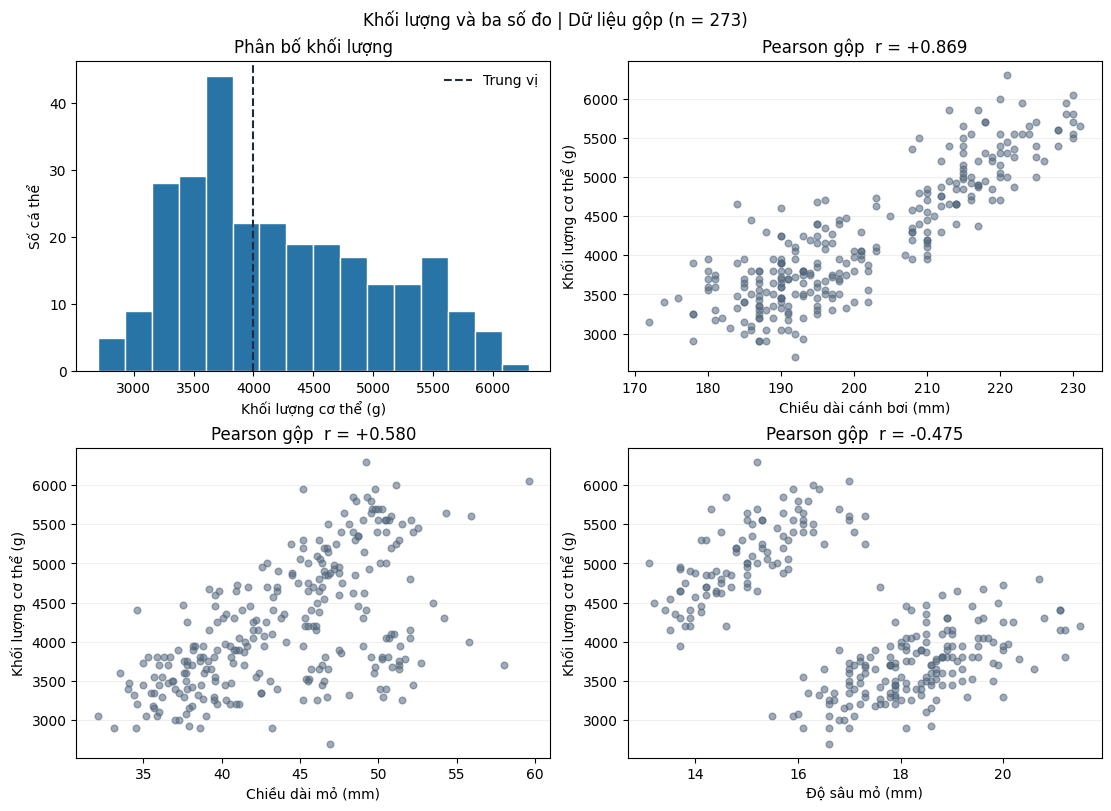

In [3]:
measurement_features = ["flipper_length_mm", "bill_length_mm", "bill_depth_mm"]
numeric_columns = [TARGET, *measurement_features]
pearson = train_data[numeric_columns].corr()

display(train_data[numeric_columns].describe().T.round(2))
display(pearson.round(3))

numeric_figure, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
hist_ax = axes.flat[0]
hist_ax.hist(y_train, bins=16, color="#2874A6", edgecolor="white")
hist_ax.axvline(y_train.median(), color="#202C3C", linestyle="--", label="Trung vị")
hist_ax.set(xlabel=LABELS[TARGET], ylabel="Số cá thể", title="Phân bố khối lượng")
hist_ax.legend(frameon=False)

for ax, feature in zip(axes.flat[1:], measurement_features):
    ax.scatter(train_data[feature], y_train, color="#52677C", alpha=0.55, s=23)
    ax.set(
        xlabel=LABELS[feature], ylabel=LABELS[TARGET],
        title=f"Pearson gộp  r = {pearson.loc[feature, TARGET]:+.3f}",
    )
    ax.grid(axis="y", alpha=0.20)

numeric_figure.suptitle(f"Khối lượng và ba số đo | Dữ liệu gộp (n = {len(train_data)})")
plt.show()

### Đối chiếu ba cách phân tầng

Bùi Tiến Lên, *Phân tích dữ liệu* (2023), trình bày Pearson và bảng chéo ở trang PDF 109. Ví dụ nghịch lý Simpson ở §8.8 (trang PDF 182–183) minh họa cách xu hướng trong từng nhóm có thể đổi dấu khi gộp. Áp dụng cách đối chiếu đó cho độ sâu mỏ và khối lượng, với ba biến phân nhóm có sẵn là loài, đảo và giới tính.

Vẽ lại cùng các điểm độ sâu mỏ–khối lượng trên ba biểu đồ có chung thang trục. Mỗi biểu đồ tô theo một nhãn. Cả ba cách dùng chung các dòng train có đủ hai giá trị đang xét và ba nhãn nhóm. So sánh các cụm màu với bảng Pearson. Sau đó dùng trung bình từng nhóm và bảng chéo với loài để giải thích kết quả. [Diễn giải và cơ sở phương pháp](../report/eda-week1.md#đối-chiếu-cách-phân-tầng)

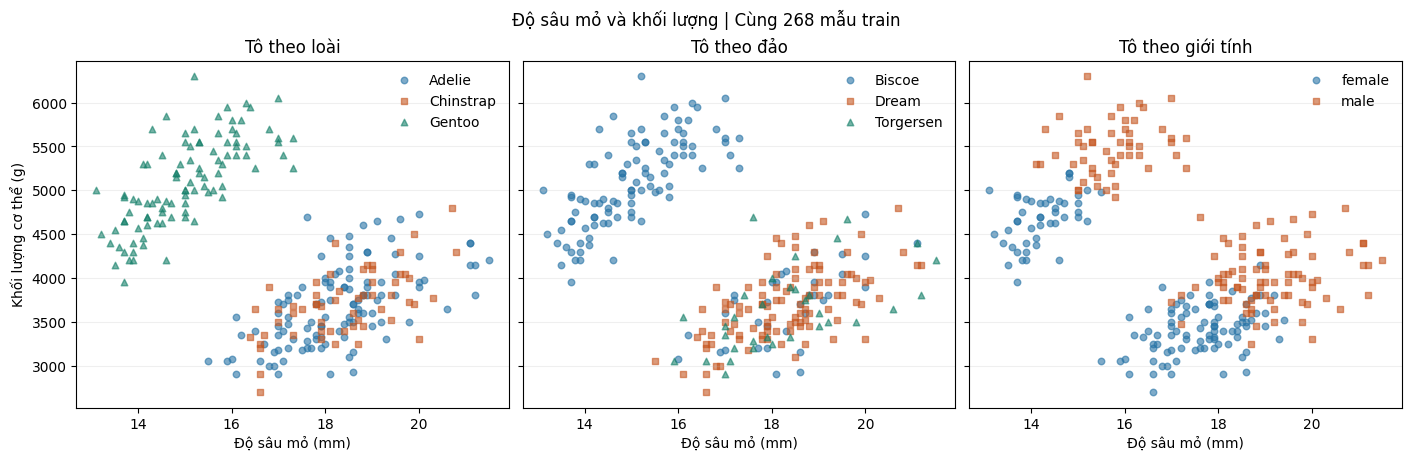

n  Pearson r  Độ sâu mỏ TB (mm)  \
Tách theo Nhóm                                                       
Gộp       Toàn bộ mẫu phân tích  268     -0.475             17.114   
Loài      Adelie                 113      0.585             18.286   
          Chinstrap               57      0.600             18.398   
          Gentoo                  98      0.718             15.015   
Đảo       Biscoe                 132     -0.388             15.875   
          Dream                  103      0.590             18.314   
          Torgersen               33      0.546             18.324   
Giới tính female                 136     -0.739             16.471   
          male                   132     -0.764             17.777   

                                 Khối lượng TB (g)  
Tách theo Nhóm                                      
Gộp       Toàn bộ mẫu phân tích           4208.209  
Loài      Adelie                          3686.062  
          Chinstrap                       3707.895  
          Gentoo                          5101.276  
Đảo       Biscoe                          4739.394  
          Dream                           3705.583  
          Torgersen                       3652.273  
Giới tính female                          3837.500  
          male                            4590.152

Loài,Adelie,Chinstrap,Gentoo
Đảo,,,
Biscoe,34,0,98
Dream,46,57,0
Torgersen,33,0,0


Loài,Adelie,Chinstrap,Gentoo
Giới tính,,,
female,59,31,46
male,54,26,52


In [4]:
depth_column = "bill_depth_mm"
group_columns = ["species", "island", "sex"]
stratification_sample = train_data.dropna(subset=[depth_column, TARGET, *group_columns])
group_colors = ["#2874A6", "#C65721", "#16806A"]
group_markers = ["o", "s", "^"]
stratification_figure, stratification_axes = plt.subplots(
    1, 3, figsize=(14, 4.5), sharex=True, sharey=True, layout="constrained",
)
strata = [("Gộp", "Toàn bộ mẫu phân tích", stratification_sample)]
for ax, column in zip(stratification_axes, group_columns):
    for index, (name, group) in enumerate(stratification_sample.groupby(column)):
        strata.append((LABELS[column], name, group))
        ax.scatter(
            group[depth_column], group[TARGET], label=name,
            color=group_colors[index % len(group_colors)],
            marker=group_markers[index % len(group_markers)], alpha=0.60, s=22,
        )
    ax.set(xlabel=LABELS[depth_column], title=f"Tô theo {LABELS[column].lower()}")
    ax.grid(axis="y", alpha=0.20)
    ax.legend(frameon=False, loc="upper right")
stratification_axes[0].set_ylabel(LABELS[TARGET])
stratification_figure.suptitle(
    f"Độ sâu mỏ và khối lượng | Cùng {len(stratification_sample)} mẫu train",
)
plt.show()

stratification_comparison = pd.DataFrame([
    {
        "Tách theo": grouping,
        "Nhóm": name,
        "n": len(group),
        "Pearson r": group[depth_column].corr(group[TARGET]),
        "Độ sâu mỏ TB (mm)": group[depth_column].mean(),
        "Khối lượng TB (g)": group[TARGET].mean(),
    }
    for grouping, name, group in strata
])
display(stratification_comparison.set_index(["Tách theo", "Nhóm"]).round(3))
for column in ("island", "sex"):
    display(pd.crosstab(stratification_sample[column], stratification_sample["species"])
            .rename_axis(index=LABELS[column], columns=LABELS["species"]))

### C. Bổ sung kiểm định tương quan trong EDA

Cell trước dùng cùng 268 điểm để đối chiếu loài, đảo và giới tính. Loài là cách duy nhất trong ba cách cho tương quan độ sâu mỏ dương ở mọi nhóm dù hệ số gộp âm. Bây giờ dùng các dòng train đủ số đo, khối lượng và loài để lượng hóa phát hiện này.

Tính Pearson r, p-value hai phía bằng hoán vị và CI 95% bootstrap theo cặp cho ba số đo, cả khi gộp và trong từng loài. Dùng Spearman để xem kết luận về chiều liên hệ có nhất quán khi dựa trên thứ hạng, vì biểu đồ độ sâu mỏ cho thấy nhiều cụm và xu hướng gộp có thể cong.

So sánh hệ số độ sâu mỏ của hồi quy gộp với hồi quy có điều chỉnh loài. Kiểm định tương tác loài × độ sâu mỏ xét H₀ rằng ba loài có cùng độ dốc. Bảng hệ số và kiểm định tương tác dùng sai số chuẩn HC3. [Cơ sở phương pháp và diễn giải](../report/eda-week1.md#tương-quan-độ-bất-định-và-nghịch-lý-simpson)

In [5]:
from IPython.display import Markdown
from source.eda_statistics import correlation_tables, depth_analysis

pearson_table, spearman_table = correlation_tables(train_data)
depth_slopes, depth_interaction = depth_analysis(train_data)
depth_tables = {
    "Pearson và CI bootstrap": pearson_table,
    "Đối chiếu Spearman": spearman_table,
    "Hệ số độ sâu mỏ (HC3)": depth_slopes,
    "Kiểm định tương tác độ sâu mỏ × loài (HC3)": pd.DataFrame([depth_interaction]),
}
with pd.option_context("display.float_format", "{:.4g}".format):
    for name, table in depth_tables.items():
        display(Markdown(f"**{name}**"))
        display(table)

**Pearson và CI bootstrap**

,Nhóm,Số đo,n,Pearson r,p hoán vị,CI 95% dưới,CI 95% trên
0,Gộp,flipper_length_mm,273,0.8691,0.0002,0.8436,0.8939
1,Gộp,bill_length_mm,273,0.5803,0.0002,0.4985,0.657
2,Gộp,bill_depth_mm,273,-0.4747,0.0002,-0.5403,-0.4109
3,Adelie,flipper_length_mm,116,0.4187,0.0002,0.276,0.5444
4,Adelie,bill_length_mm,116,0.5157,0.0002,0.3891,0.6395
5,Adelie,bill_depth_mm,116,0.5895,0.0002,0.4773,0.6876
6,Chinstrap,flipper_length_mm,57,0.6312,0.0002,0.4765,0.7599
7,Chinstrap,bill_length_mm,57,0.4976,0.0002,0.3175,0.652
8,Chinstrap,bill_depth_mm,57,0.5996,0.0002,0.397,0.7463
9,Gentoo,flipper_length_mm,100,0.6926,0.0002,0.5864,0.782


**Đối chiếu Spearman**

,Nhóm,Số đo,n,Spearman ρ
0,Gộp,flipper_length_mm,273,0.8356
1,Gộp,bill_length_mm,273,0.5716
2,Gộp,bill_depth_mm,273,-0.4353
3,Adelie,bill_depth_mm,116,0.615
4,Chinstrap,bill_depth_mm,57,0.5636
5,Gentoo,bill_depth_mm,100,0.7508


**Hệ số độ sâu mỏ (HC3)**

,Mô hình phụ,n,Hệ số (g/mm),t HC3,p HC3,CI 95% dưới,CI 95% trên
0,Gộp,273,-197.5,-10.8,7.529e-23,-233.5,-161.5
1,Điều chỉnh theo loài,273,253.4,14.02,6.606e-34,217.9,289
2,Adelie,116,216.7,9.304,1.165e-15,170.6,262.9
3,Chinstrap,57,201.4,4.676,1.938e-05,115.1,287.7
4,Gentoo,100,353,10.02,1.119e-16,283,422.9


**Kiểm định tương tác độ sâu mỏ × loài (HC3)**

,Kiểm định,n,F,df1,df2,p
0,Độ sâu mỏ × loài,273,5.922,2,267,0.003045


**Kết quả mục C.** Pearson giữa độ sâu mỏ và khối lượng là **−0,475 khi gộp**, nhưng dương ở Adelie, Chinstrap và Gentoo, lần lượt **+0,590**, **+0,600** và **+0,714**. Spearman cho cùng kiểu đảo dấu. Gentoo có mỏ nông hơn và nặng hơn trung bình, nên việc gộp các cụm theo loài làm đổi chiều liên hệ, một biểu hiện kiểu nghịch lý Simpson trong mẫu.

Hệ số gộp **−197,5 g/mm** đổi thành **+253,4 g/mm** khi điều chỉnh theo loài. Tương tác có **p = 0,00305**, cho thấy độ dốc chung chỉ tóm tắt liên hệ trong mẫu. Để hiểu thêm chênh lệch khối lượng giữa các nhóm, mục D xét riêng loài và giới tính.

### D. Kiểm định khác biệt giữa các nhóm

Dùng boxplot và số liệu mô tả để xem vị trí, mức phân tán và số mẫu của từng nhóm. Welch ANOVA trên 273 mẫu xét H₀ rằng khối lượng trung bình của ba loài bằng nhau, cho phép phương sai khác nhau. So sánh từng cặp loài để ước lượng nhóm nào khác và chênh bao nhiêu gram.

Trên 268 mẫu có giới tính, Welch t-test xét chênh lệch trung bình đực–cái trong từng loài. Hai họ so sánh Welch hiệu chỉnh p-value Holm riêng, kèm CI 95% của từng chênh lệch. Mô hình loài × giới tính xét H₀ rằng chênh lệch đực–cái bằng nhau giữa các loài. [Số liệu và cơ sở phương pháp](../report/eda-week1.md#khác-biệt-khối-lượng-theo-loài-và-giới-tính)

,n,median_g
species,,
Adelie,116,3700.0
Chinstrap,57,3700.0
Gentoo,100,5050.0


n  median_g
species   sex                 
Adelie    female  59    3350.0
          male    54    3962.5
          NaN      3    3700.0
Chinstrap female  31    3525.0
          male    26    3950.0
Gentoo    female  46    4700.0
          male    52    5500.0
          NaN      2    4762.5

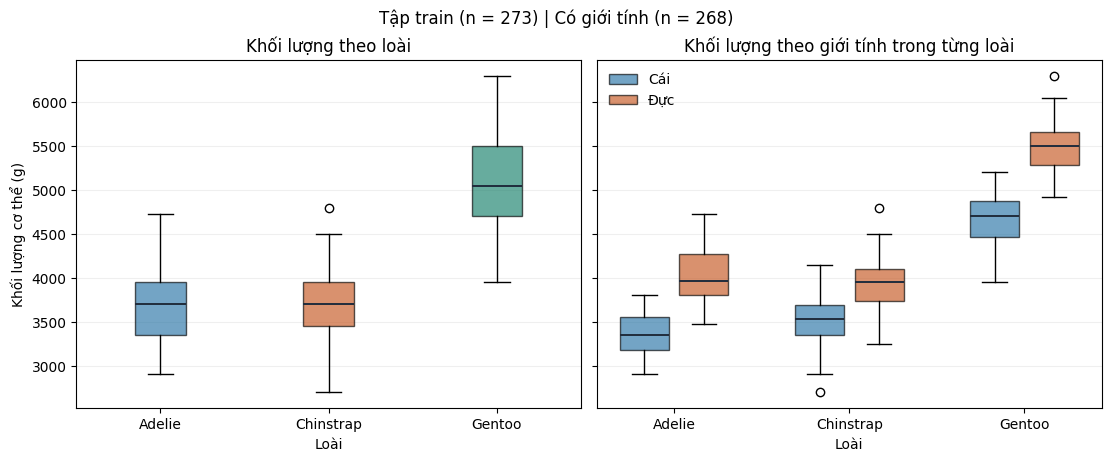

**Khối lượng theo loài và giới tính**

n  mean_g  sd_g  median_g  q1_g  q3_g  iqr_g
species   sex                                                   
Adelie    Tất cả  116    3689 448.3      3700  3350  3950    600
          female   59    3356 254.5      3350  3175  3550    375
          male     54    4047 323.3      3962  3800  4269  468.8
Chinstrap Tất cả   57    3708 385.3      3700  3450  3950    500
          female   31    3518   297      3525  3350  3688  337.5
          male     26    3935 358.3      3950  3731  4100  368.8
Gentoo    Tất cả  100    5094 500.9      5050  4700  5500    800
          female   46    4671 292.7      4700  4462  4875  412.5
          male     52    5482 302.3      5500  5288  5662    375

**Welch ANOVA theo loài**

,Kiểm định,n,F,df1,df2,p
0,Welch ANOVA theo loài,273,274.1,2,155.7,9.737e-52


**So sánh từng cặp loài · Welch và Holm**

,So sánh,n1,n2,Chênh lệch (g),CI 95% dưới,CI 95% trên,t Welch,df,p,p Holm
0,Chinstrap − Adelie,57,116,18.67,-111.6,149,0.2835,127.8,0.7773,0.7773
1,Gentoo − Adelie,100,116,1405,1277,1534,21.58,200.6,3.546e-54,1.064e-53
2,Gentoo − Chinstrap,100,57,1387,1245,1528,19.39,141.6,1.111e-41,2.222e-41


... (4 outputs left out)

**Thay đổi chênh lệch đực − cái so với Adelie (HC3)**

,difference_g,ci_low_g,ci_high_g,t_hc3,p_hc3,p_holm
C(species)[T.Chinstrap]:C(sex)[T.male],-274,-482,-65.89,-2.593,0.01006,0.02012
C(species)[T.Gentoo]:C(sex)[T.male],120.7,-41.46,282.9,1.466,0.1439,0.1439


species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,34,0,100
Dream,46,57,0
Torgersen,36,0,0


,n,median_g
year,,
2007,87,3900.0
2008,94,4275.0
2009,92,3987.5


In [6]:
from source.eda_statistics import group_analysis

species_groups = dict(iter(train_data.groupby("species")))
species_colors = dict(zip(species_groups, group_colors))

species_summary = train_data.groupby("species")[TARGET].agg(n="size", median_g="median")
sex_summary = train_data.groupby(["species", "sex"], dropna=False)[TARGET].agg(
    n="size", median_g="median",
)
display(species_summary)
display(sex_summary)

category_figure, (species_ax, sex_ax) = plt.subplots(
    1, 2, figsize=(11, 4.5), sharey=True, layout="constrained",
)
species_box = species_ax.boxplot(
    [group[TARGET] for group in species_groups.values()],
    tick_labels=list(species_groups), patch_artist=True,
    medianprops={"color": "#202C3C", "linewidth": 1.4},
)
for box, color in zip(species_box["boxes"], species_colors.values()):
    box.set_facecolor(color)
    box.set_alpha(0.65)
species_ax.set(xlabel=LABELS["species"], ylabel=LABELS[TARGET], title="Khối lượng theo loài")

positions = np.arange(1, len(species_groups) + 1)
sex_legend = []
for sex, label, color, offset in [
    ("female", "Cái", "#2874A6", -0.17),
    ("male", "Đực", "#C65721", 0.17),
]:
    boxes = sex_ax.boxplot(
        [group.loc[group["sex"] == sex, TARGET] for group in species_groups.values()],
        positions=positions + offset, widths=0.28, patch_artist=True,
        manage_ticks=False, medianprops={"color": "#202C3C", "linewidth": 1.4},
    )
    for box in boxes["boxes"]:
        box.set_facecolor(color)
        box.set_alpha(0.65)
    sex_legend.append((boxes["boxes"][0], label))

sex_ax.set_xticks(positions, list(species_groups))
sex_ax.set(xlabel=LABELS["species"], title="Khối lượng theo giới tính trong từng loài")
sex_ax.legend(*zip(*sex_legend), frameon=False)
for ax in (species_ax, sex_ax):
    ax.grid(axis="y", alpha=0.20)

known_sex_count = int(train_data["sex"].notna().sum())
category_figure.suptitle(f"Tập train (n = {len(train_data)}) | Có giới tính (n = {known_sex_count})")
plt.show()

group_summary, species_pairs, sex_pairs, species_anova, sex_interaction, sex_gap_changes = (
    group_analysis(train_data)
)
group_tables = {
    "Khối lượng theo loài và giới tính": group_summary,
    "Welch ANOVA theo loài": pd.DataFrame([species_anova]),
    "So sánh từng cặp loài · Welch và Holm": species_pairs,
    "Đực − cái trong từng loài · Welch và Holm": sex_pairs,
    "Kiểm định tương tác loài × giới tính (HC3)": pd.DataFrame([sex_interaction]),
    "Thay đổi chênh lệch đực − cái so với Adelie (HC3)": sex_gap_changes,
}
with pd.option_context("display.float_format", "{:.4g}".format):
    for name, table in group_tables.items():
        display(Markdown(f"**{name}**"))
        display(table)

display(pd.crosstab(train_data["island"], train_data["species"]))
display(train_data.groupby("year")[TARGET].agg(n="size", median_g="median"))

**Kết quả mục D.** Welch ANOVA cho **F(2, 155,73) = 274,07**. Gentoo nặng hơn trung bình khoảng **1,39–1,41 kg** so với hai loài kia. Chênh lệch Chinstrap − Adelie là **18,7 g**, với CI 95% **[−111,6; 149,0] g**, nên mức chênh giữa hai loài này còn bất định. Nhóm đực nặng hơn trung bình trong cả ba loài, với mức chênh khoảng **417–812 g**. Kiểm định tương tác (**p = 0,00157**) cho thấy mức chênh đực–cái thay đổi theo loài trong mẫu.

Số mẫu theo giới tính chỉ tính các cá thể có thông tin. Các khoảng tin cậy là khoảng riêng lẻ. Các kiểm định dựa vào giả định các cá thể độc lập, và kết quả mô tả liên hệ trong mẫu quan sát.

### E. Kiểm tra đặc điểm dữ liệu và giải thích lựa chọn mô hình

Vẽ LOWESS cho cả ba số đo khi gộp và khi tách theo loài để xem dấu hiệu cong có còn rõ sau khi phân nhóm. Kiểm tra độ phân tán, độ lệch và các điểm ngoài hàng rào 1,5 × IQR ở cả hai phạm vi. Ma trận Pearson giữa ba số đo cho biết mức độ liên hệ giữa các đầu vào. [Phương pháp và biểu đồ](../report/eda-week1.md#lowess-điểm-bất-thường-và-dạng-mô-hình)

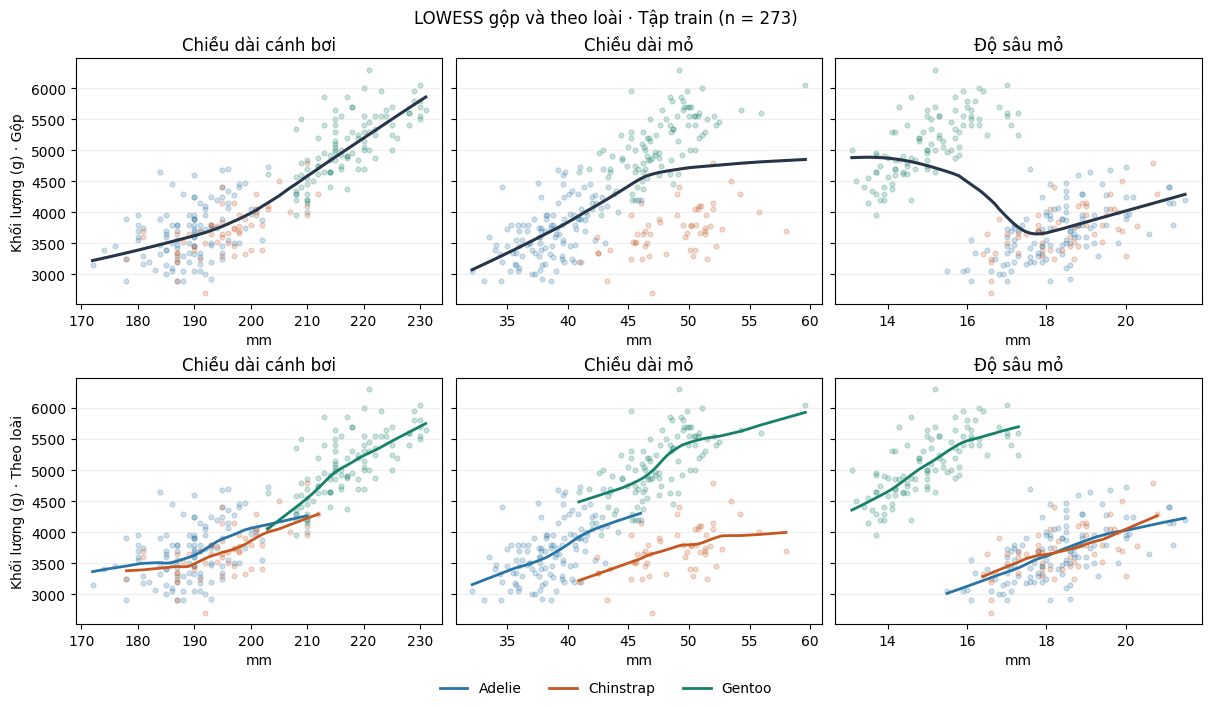

**Phân bố và ngưỡng IQR**

,Nhóm,Biến,n,SD,Trung vị,IQR,Skewness,Cận dưới,Cận trên,Số điểm gắn cờ
0,Gộp,flipper_length_mm,273,14.2,197,24,0.313,154,250,0
1,Gộp,bill_length_mm,273,5.537,44.5,9.4,0.03206,25.1,62.7,0
2,Gộp,bill_depth_mm,273,1.957,17.3,3.1,-0.125,10.85,23.25,0
3,Gộp,body_mass_g,273,814.2,4000,1300,0.4661,1600,6800,0
4,Adelie,flipper_length_mm,116,6.604,190,7.25,0.1216,175.1,204.1,4
5,Adelie,bill_length_mm,116,2.585,38.6,3.725,0.02451,31.19,46.09,0
6,Adelie,bill_depth_mm,116,1.219,18.3,1.425,0.396,15.34,21.04,6
7,Adelie,body_mass_g,116,448.3,3700,600,0.325,2450,4850,0
8,Chinstrap,flipper_length_mm,57,7.259,196,9,-0.008136,177.5,213.5,0
9,Chinstrap,bill_length_mm,57,3.508,49.5,5.1,-0.03306,38.55,58.95,0


**Quan sát gắn cờ IQR**

,Nhóm,Biến,Chỉ số CSV,Loài,Giá trị
0,Adelie,flipper_length_mm,95,Adelie,208
1,Adelie,flipper_length_mm,20,Adelie,174
2,Adelie,flipper_length_mm,28,Adelie,172
3,Adelie,flipper_length_mm,129,Adelie,210
4,Adelie,bill_depth_mm,61,Adelie,21.1
5,Adelie,bill_depth_mm,19,Adelie,21.5
6,Adelie,bill_depth_mm,13,Adelie,21.2
7,Adelie,bill_depth_mm,35,Adelie,21.1
8,Adelie,bill_depth_mm,14,Adelie,21.1
9,Adelie,bill_depth_mm,49,Adelie,21.2


**Tương quan giữa ba số đo**

,flipper_length_mm,bill_length_mm,bill_depth_mm
flipper_length_mm,1,0.6513,-0.5734
bill_length_mm,0.6513,1,-0.2264
bill_depth_mm,-0.5734,-0.2264,1


In [7]:
from source.eda_statistics import distribution_audit, plot_lowess

eda_lowess_figure = plot_lowess(train_data)
plt.show()
distribution, flags = distribution_audit(train_data)
shape_tables = {
    "Phân bố và ngưỡng IQR": distribution,
    "Quan sát gắn cờ IQR": flags,
    "Tương quan giữa ba số đo": train_data[measurement_features].corr(),
}
with pd.option_context("display.float_format", "{:.4g}".format):
    for name, table in shape_tables.items():
        display(Markdown(f"**{name}**"))
        display(table)

Đường LOWESS gộp của độ sâu mỏ đổi hướng giữa các cụm loài. Các đường theo loài đều có xu hướng tăng. Quy tắc IQR gắn **13 cờ khi xét theo loài** và **0 cờ khi gộp**. Chiều dài cánh bơi và chiều dài mỏ có **r = 0,651**.

| Mô hình | Dấu hiệu cần kiểm tra khi huấn luyện |
| --- | --- |
| OLS | Dùng làm mốc so sánh. Kiểm tra độ phù hợp của dạng tuyến tính, nhất là với độ sâu mỏ có độ dốc thay đổi theo loài. |
| Ridge | Kiểm tra khả năng co hệ số khi các số đo có tương quan với nhau. |
| Spline | Kiểm tra qua CV xem cho phép đường cong có giảm sai số sau khi đã đưa loài vào mô hình. |
| Huber | Đối chiếu các điểm gắn cờ IQR với các phần dư lớn rồi kiểm tra độ nhạy của kết quả. |

Tiếp theo, dùng OLS với cùng 5 fold trên train để đối chiếu bộ đủ năm biến, bộ chỉ gồm ba số đo và các cấu hình bỏ từng biến. Tiền xử lý được fit lại trong từng fold. [Thiết kế so sánh](../report/eda-week1.md#kiểm-tra-bộ-năm-biến-bằng-cross-validation)

In [8]:
from source.eda_statistics import feature_cv

with pd.option_context("display.float_format", "{:.4g}".format):
    display(feature_cv(train_data))

,MAE TB,MAE SD,MSE TB,MSE SD,RMSE TB,RMSE SD,R² TB,R² SD,Δ MAE so với đủ 5 biến (g)
Bộ biến,,,,,,,,,
Đủ 5 biến,225.6,17.19,8.404e+04,1.168e+04,289.3,21.08,0.8662,0.02278,0
Chỉ ba số đo,321.8,11.3,1.655e+05,5713,406.7,7.057,0.734,0.04641,96.22
Bỏ flipper_length_mm,233.9,20.7,8.964e+04,1.476e+04,298.5,26.06,0.8576,0.02611,8.316
Bỏ bill_length_mm,228.2,16.11,8.439e+04,1.032e+04,290,18.1,0.8661,0.01574,2.583
Bỏ bill_depth_mm,233.4,12.76,8.809e+04,1.183e+04,296.2,20.91,0.8593,0.02731,7.807
Bỏ species,284,8.512,1.226e+05,8556,350,12.39,0.8044,0.02579,58.44
Bỏ sex,251.9,15.97,1.045e+05,9590,323,14.99,0.8325,0.03088,26.34


#### Kết luận về năm biến đầu vào

Bộ đủ năm biến có MAE trung bình **225,59 g**, so với **321,81 g** khi chỉ dùng ba số đo. Bỏ riêng loài hoặc giới tính làm MAE tăng khoảng **58,44 g** và **26,34 g**. Bỏ lần lượt chiều dài cánh bơi, chiều dài mỏ và độ sâu mỏ làm MAE tăng khoảng **8,32 g**, **2,58 g** và **7,81 g**. Chênh lệch khi bỏ chiều dài mỏ nhỏ so với độ phân tán giữa các fold.

Giữ chung **chiều dài cánh bơi, chiều dài mỏ, độ sâu mỏ, loài và giới tính**, với giả định biết loài và giới tính lúc dự đoán. Trong mẫu, đảo gắn chặt với loài, còn năm chỉ trải từ 2007 đến 2009. Giữ hai cột này ngoài bộ đầu vào hiện tại. [Lý do theo từng biến](../report/eda-week1.md#đề-xuất-bộ-biến-chung)

## 3. Thiết kế và huấn luyện mô hình

Điền estimator do bạn chọn vào `ESTIMATOR` trong tệp phụ trách. Vị trí còn trống sẽ chạy cấu hình mẫu để kiểm tra pipeline và được đánh dấu **Chưa chọn** trong bảng.

Pipeline chung điền trung vị và chuẩn hóa cho biến số. Với biến phân loại, pipeline điền mức phổ biến nhất và mã hóa one-hot với một mức tham chiếu.

**TODO** Mỗi người chọn một thuật toán hồi quy tuyến tính riêng, ghi lý do chọn và các siêu tham số đã dùng. Sau khi sửa tệp, khởi động lại kernel và chạy toàn bộ notebook. [M1](models/m1.py) · [M2](models/m2.py) · [M3](models/m3.py) · [M4](models/m4.py)

M4 dùng Huber Regression với epsilon = 1,2 và alpha = 0,001, chọn theo MAE bằng 5-fold CV trên train. [Tinh chỉnh, so sánh với OLS và phân tích độ nhạy](../report/huber-m4-week2.md)

In [ ]:
model_modules = (m1, m2, m3, m4)
models = {}
model_info = []
for module in model_modules:
    model = module.build_model().fit(train_data[FEATURES], y_train)
    models[module.NAME] = model
    model_info.append({
        "Mô hình": module.NAME,
        "Estimator đang chạy": type(model.named_steps["regression"]).__name__,
        "Trạng thái": "Chưa chọn (mẫu)" if module.ESTIMATOR is None else "Đã chọn",
    })
display(pd.DataFrame(model_info).set_index("Mô hình"))

## 4. Đánh giá và diễn giải

So sánh MAE, MSE, RMSE và R² của các mô hình trên cùng tập kiểm tra. MSE tính bằng g², MAE và RMSE tính bằng gram. R² không có đơn vị. Chọn mô hình ở danh sách bên dưới để xem hệ số và phần dư của mô hình đó.

**TODO** Viết nhận xét sau khi bốn thuật toán đã được chọn. So sánh mức chênh lệch sai số, phần dư và hệ số. Với biến số, hệ số tính theo gram trên một độ lệch chuẩn của đầu vào, giữ các biến còn lại cố định. Với biến phân loại, so sánh với mức tham chiếu hiển thị dưới bảng.

In [ ]:
predictions = {}
scores = []
for name, model in models.items():
    y_pred = model.predict(test_data[FEATURES])
    predictions[name] = y_pred
    scores.append({"Mô hình": name, **regression_metrics(y_test, y_pred)})

results = pd.DataFrame(scores).set_index("Mô hình")
display(results.round({"MAE (g)": 1, "MSE (g²)": 1, "RMSE (g)": 1, "R²": 3}))

In [ ]:
def show_diagnostics(model_name):
    model = models[model_name]
    preprocessor = model.named_steps["preprocess"]
    regression = model.named_steps["regression"]
    coefficient_model = getattr(regression, "estimator_", regression)

    if hasattr(coefficient_model, "coef_") and hasattr(coefficient_model, "intercept_"):
        intercept = np.asarray(coefficient_model.intercept_).item()
        print(f"{model_name} | Hệ số chặn: {intercept:.2f} g")
        display(pd.Series(
            np.ravel(coefficient_model.coef_),
            index=preprocessor.get_feature_names_out(),
            name="Hệ số",
        ).round(3).to_frame())
    else:
        print(f"{model_name} | Xem phần dư bên dưới và tra tài liệu estimator để trích hệ số.")

    categorical_features = [
        feature for feature in FEATURES if feature in CATEGORICAL
    ]
    if categorical_features:
        encoder = preprocessor.named_transformers_["categorical"].named_steps["encoder"]
        for feature, levels, reference_index in zip(
            categorical_features, encoder.categories_, encoder.drop_idx_
        ):
            print(f"Mức tham chiếu của {feature}: {levels[reference_index]}")

    y_pred = predictions[model_name]
    fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    ax.scatter(y_pred, y_test - y_pred, alpha=0.65, color="#246b83")
    ax.axhline(0, color="#475569", linestyle="--")
    ax.set(xlabel="Dự đoán (g)", ylabel="Thực tế − dự đoán (g)", title="Phần dư trên tập kiểm tra")
    plt.show()
    plt.close(fig)

diagnostics = widgets.interactive(
    show_diagnostics, model_name=widgets.Dropdown(options=list(models), description="Mô hình"),
)
display(diagnostics)

## 5. Giao diện dự đoán

Chọn mô hình và chỉnh đầu vào, sau đó bấm **Dự đoán**. Biểu đồ hiển thị dữ liệu huấn luyện và dự đoán khi thay đổi biến trên trục ngang, giữ các giá trị đầu vào còn lại theo biểu mẫu.

**TODO** Chuẩn bị hai ví dụ để demo và ghi lại giá trị đầu vào, dự đoán và thay đổi trên biểu đồ.

In [ ]:
model_picker = widgets.Dropdown(
    options=list(models), description="Mô hình",
    style={"description_width": "initial"},
)
plot_picker = widgets.Dropdown(
    options=[(LABELS[feature], feature) for feature in FEATURES],
    value=FEATURES[0],
    description="Biến trên biểu đồ", style={"description_width": "initial"},
)
predict_button = widgets.Button(description="Dự đoán", button_style="primary")
prediction_output = widgets.Output()
controls = {}

for feature in FEATURES:
    observed = train_data[feature].dropna()
    if feature in CATEGORICAL:
        controls[feature] = widgets.Dropdown(
            options=sorted(observed.unique()),
            value=observed.mode().iloc[0],
            description=LABELS[feature],
            style={"description_width": "initial"},
        )
    else:
        slider_class = widgets.IntSlider if feature == "year" else widgets.FloatSlider
        controls[feature] = slider_class(
            value=observed.median(), min=observed.min(), max=observed.max(),
            step=1 if feature == "year" else 0.1,
            description=LABELS[feature],
            style={"description_width": "initial"},
        )

def clear_prediction(_change):
    prediction_output.clear_output(wait=False)

def render_prediction(_button=None):
    name = model_picker.value
    focus = plot_picker.value
    input_values = {feature: control.value for feature, control in controls.items()}
    estimate = models[name].predict(pd.DataFrame([input_values]))[0]

    control = controls[focus]
    is_categorical = focus in CATEGORICAL
    if is_categorical:
        values = list(control.options)
    elif focus == "year":
        values = list(range(control.min, control.max + 1))
    else:
        values = np.linspace(control.min, control.max, 80)
    scenarios = pd.DataFrame(input_values, index=range(len(values)))
    scenarios[focus] = values
    trend = models[name].predict(scenarios)

    with prediction_output:
        prediction_output.clear_output(wait=True)
        print(f"Khối lượng dự đoán: {estimate:,.0f} g")
        fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
        observed = train_data.dropna(subset=[focus])
        if is_categorical:
            positions = {value: index for index, value in enumerate(values)}
            ax.scatter(observed[focus].map(positions), observed[TARGET], alpha=0.25,
                       color="#64748b", label="Dữ liệu huấn luyện")
            ax.scatter(list(positions.values()), trend, marker="D",
                       color="#246b83", label="Dự đoán theo mức")
            ax.set_xticks(list(positions.values()), values)
            selected_x = positions[input_values[focus]]
        else:
            ax.scatter(observed[focus], observed[TARGET], alpha=0.25,
                       color="#64748b", label="Dữ liệu huấn luyện")
            ax.plot(values, trend, color="#246b83", label="Dự đoán theo đầu vào")
            selected_x = input_values[focus]
        ax.scatter(selected_x, estimate, s=85, color="#d76a2c", edgecolor="white",
                   zorder=3, label="Giá trị đã nhập")
        ax.set(xlabel=LABELS[focus], ylabel=LABELS[TARGET])
        ax.legend()
        plt.show()
        plt.close(fig)

model_picker.observe(clear_prediction, names="value")
predict_button.on_click(render_prediction)
display(widgets.VBox([
    model_picker, *controls.values(), plot_picker, predict_button, prediction_output,
]))
render_prediction()

## 6. Kết luận và tài liệu tham khảo

**TODO** Tóm tắt câu trả lời cho mục tiêu của nhóm. Dẫn số liệu từ bảng đánh giá, biểu đồ hoặc hệ số cho từng nhận xét chính. Ghi các giới hạn quan sát được và đưa phần trình bày đầy đủ vào báo cáo.

Horst, A. M., Hill, A. P., & Gorman, K. B. (2020). *palmerpenguins: Palmer Archipelago (Antarctica) penguin data*. [DOI 10.5281/zenodo.3960218](https://doi.org/10.5281/zenodo.3960218)